<div style="background-color:#ffffff; padding:14px 20px; border-radius:8px; display:flex; align-items:center; gap:16px;">
    <img src="https://s3.amazonaws.com/media-p.slid.es/uploads/1485763/images/9060062/Header.png" width="60"/>
    <div>
        <h1 style="font-size:26px; color:#6A0DAD; margin:0; white-space:nowrap;">Árboles con Fronteras Curvas</h1>
        <p style="font-size:14px; color:#555; margin:2px 0 0 0;">Sesión 4 &middot; Extra &middot; Prof. Daniel Rambaut</p>
    </div>
</div>

En la sesión 4 vimos que un árbol de decisión **CART** divide el espacio con cortes rectos paralelos a los ejes: por eso sus regiones parecen "escaleras".

La pregunta natural: **¿y si el árbol cortara con curvas?**

$$\text{¿cortes } x_j \le t \ \longrightarrow \ \text{cortes curvos?}$$

Este notebook construye esa idea **tres veces, de menor a mayor ambición**:

- **Sección A** — El truco del *espacio ampliado*: agregamos features polinómicas y el mismo CART produce curvas (sin escribir una línea de algoritmo nuevo).
- **Sección B** — **Árbol cuadrático**: nuestra primera implementación propia; cada nodo corta con la frontera de una QDA (elipses, parábolas, hipérbolas).
- **Sección C** — **Árbol híbrido**: cada nodo interno *contiene un clasificador completo* (regresión logística de la sesión 3, o SVM con kernel RBF) y corta con su frontera.

**¿Estamos reinventando algo que ya existe?** Sí (y eso es buena señal): esta familia se llama **árboles oblicuos** (*oblique trees*, OC1, Murthy 1993), **árboles funcionales** (Gama 2004) y, en su versión con redes neuronales por nodo, *neural decision trees* (Kontschieder 2015). La razón por la que CART sigue siendo el estándar la discutimos al final: interpretabilidad y costo de búsqueda.

> **Nota técnica:** los controles interactivos (sliders, botones) usan `ipywidgets`. Debes ejecutar este notebook en VS Code o Jupyter clásico, no como script.

<div style="background-color:#; border-left:4px solid #2471A3; padding:10px 18px; margin:8px 0; border-radius:4px; font-size:14px;">

<p style="font-size:15px; font-weight:600; margin:0 0 8px 0;">Sistema de autoevaluación</p>

Como en el notebook de la sesión, hay ejercicios con la función `verificar()`. Ejecuta la celda del banco **una sola vez**; solo guarda huellas (hashes) de las respuestas.

</div>

In [1]:
import hashlib

_banco_respuestas = {}

def _hash(s):
    return hashlib.sha256(s.encode("utf-8")).hexdigest()

def _registrar(id_preg, hash_correcto, tipo="texto", precision=None, pista=None):
    _banco_respuestas[id_preg] = {"hash": hash_correcto, "tipo": tipo, "precision": precision, "pista": pista}

def verificar(id_preg, respuesta):
    info = _banco_respuestas.get(id_preg)
    if info is None:
        print(f"No reconozco el ejercicio '{id_preg}'.")
        return
    if info["tipo"] == "numero":
        try:
            texto = f"{float(respuesta):.{info['precision']}f}"
        except (TypeError, ValueError):
            print("Esa respuesta no parece un número. Intenta de nuevo.")
            return
    else:
        texto = str(respuesta).strip().lower()
    if _hash(texto) == info["hash"]:
        print("Correcto.")
    else:
        msg = "Incorrecto, intenta de nuevo."
        if info["pista"]:
            msg += f" Pista: {info['pista']}"
        print(msg)

_registrar("ejA_conica",        "ca978112ca1bbdcafac231b39a23dc4da786eff8147c4e72b9807785afee48bb", pista="La frontera perfecta para círculos concéntricos es x1² + x2² = r². ¿Qué cónica es esa?")
_registrar("ejB_mahalanobis",   "3e23e8160039594a33894f6564e1b1348bbd7a0088d42c4acb73eeaed59c009d", pista="Fíjate en el papel de Σ_k⁻¹: reescala y rota los ejes antes de medir la distancia.")
_registrar("ejC_gamma",         "3e23e8160039594a33894f6564e1b1348bbd7a0088d42c4acb73eeaed59c009d", pista="γ controla el ancho de las campanas gaussianas centradas en los vectores de soporte.")
_registrar("ejD_por_que_cart",  "3e23e8160039594a33894f6564e1b1348bbd7a0088d42c4acb73eeaed59c009d", pista="Piensa en cuántos candidatos debe evaluar CART en cada nodo, y en cómo se lee un nodo como regla.")

print("Sistema de autoevaluación listo.")

Sistema de autoevaluación listo.


---
# <FONT SIZE=5 COLOR="purple"> 0. Setup: datos donde CART sufre </FONT>

Para que el contraste se vea, usamos dos datasets sintéticos de 2 variables (para poder dibujar):

- **Círculos concéntricos**: una clase rodea a la otra. *Ningún* corte recto por bueno que sea puede separarlas de un golpe.
- **Lunas** (make_moons): dos medias lunas entrelazadas.

La herramienta central es la **región de decisión**: evaluamos el modelo en una malla de puntos $(x_1, x_2)$ y pintamos cada celda según la predicción:

$$\hat{y}(x) = \text{modelo.predict}(x), \qquad x \in \text{malla}$$

El color del fondo *es* la partición del espacio que aprendió el modelo: exactamente lo que queremos comparar entre árboles.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.tree                 import DecisionTreeClassifier
from sklearn.preprocessing        import PolynomialFeatures, StandardScaler
from sklearn.pipeline             import make_pipeline
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.linear_model         import LogisticRegression
from sklearn.svm                  import SVC
from sklearn.datasets             import make_circles, make_moons
from sklearn.model_selection      import train_test_split

from ipywidgets import interact, IntSlider, FloatLogSlider, ToggleButtons, Dropdown
from IPython.display import display

RNG = 42
plt.rcParams["figure.dpi"] = 110

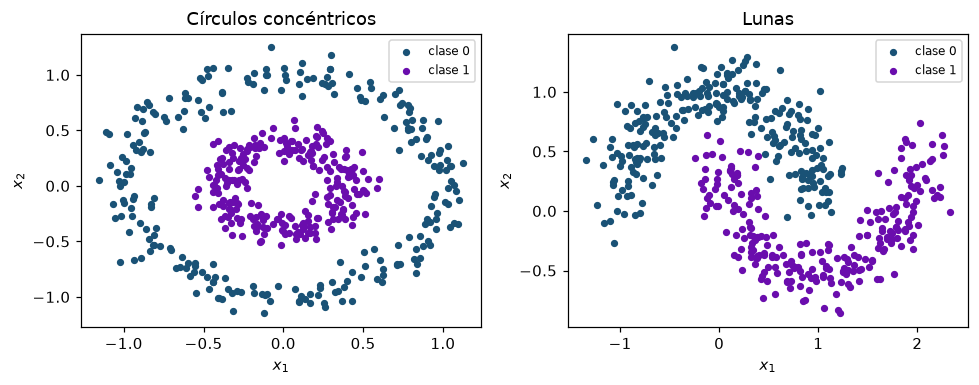

In [3]:
def frontera_decision(modelo, X, y, ax=None, titulo="", resolucion=220,
                     etiquetas=("$x_1$", "$x_2$")):
    '''Dibuja las regiones de decisión de `modelo` encima de los puntos (X, y).'''
    ax = ax or plt.gca()
    x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx0, xx1 = np.meshgrid(np.linspace(x0_min, x0_max, resolucion),
                           np.linspace(x1_min, x1_max, resolucion))
    Z = modelo.predict(np.c_[xx0.ravel(), xx1.ravel()]).reshape(xx0.shape)
    ax.contourf(xx0, xx1, Z, levels=[-0.5, 0.5, 1.5],
                colors=["#AED6F1", "#D7BDE8"], alpha=0.55)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="#1A5276", s=15,
               edgecolor="white", linewidth=0.4, label="clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#6A0DAD", s=15,
               edgecolor="white", linewidth=0.4, label="clase 1")
    ax.set_title(titulo)
    ax.set_xlabel(etiquetas[0]); ax.set_ylabel(etiquetas[1])
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

def acc(modelo, X, y):
    return (np.asarray(modelo.predict(X)) == np.asarray(y)).mean()

X_circ, y_circ = make_circles(n_samples=500, noise=0.08, factor=0.4, random_state=RNG)
X_luna, y_luna = make_moons(n_samples=500, noise=0.15, random_state=RNG)

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_circ, y_circ, test_size=0.3,
                                              random_state=RNG, stratify=y_circ)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_luna, y_luna, test_size=0.3,
                                              random_state=RNG, stratify=y_luna)

DATASETS = {
    "Círculos": (Xc_tr, yc_tr, Xc_te, yc_te),
    "Lunas":    (Xl_tr, yl_tr, Xl_te, yl_te),
}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, X, y, nombre in [(axes[0], X_circ, y_circ, "Círculos concéntricos"),
                         (axes[1], X_luna, y_luna, "Lunas")]:
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="#1A5276", s=14, label="clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#6A0DAD", s=14, label="clase 1")
    ax.set_title(nombre); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

---
# <FONT SIZE=5 COLOR="red"> 1. Sección A — Curvas sin salir de sklearn: el espacio ampliado </FONT>

## <FONT SIZE=4 COLOR="red"> 1.1 Por qué CART dibuja escaleras </FONT>

En cada nodo, `DecisionTreeClassifier` solo sabe hacer una cosa: comparar **una** variable contra un umbral,

$$x_j \le t$$

**¿Qué dice esta desigualdad?** Que el corte es un hiperplano *paralelo a un eje*. En 2D, con $j=1$ es la recta vertical $x_1 = t$ y con $j=2$ la horizontal $x_2 = t$: el árbol solo puede elegir entre **dos direcciones** por nodo. Unir muchos cortes así produce regiones en forma de escalera. Para las lunas alcanza (con paciencia); para los círculos concéntricos es una tortura: cada escalón deja puntos mal clasificados.

## <FONT SIZE=4 COLOR="red"> 1.2 La idea: no cambies el árbol, dobla el espacio </FONT>

Definimos un mapa $\phi$ que agrega potencias y productos de las variables (grado 2):

$$\phi(x_1, x_2) = \big(\,x_1,\;\; x_2,\;\; x_1^2,\;\; x_1 x_2,\;\; x_2^2\,\big)$$

**¿Qué es cada elemento?** Los monomios de grado $\le 2$: las dos variables originales más las tres combinaciones cuadráticas. Entrenamos el mismo CART, pero sobre $\phi(x)$ en vez de $x$.

**¿Por qué eso produce curvas?** Un corte del árbol en el espacio ampliado sigue siendo "columna $\le$ umbral", pero las columnas ahora son $x_1^2$, $x_1 x_2$, $x_2^2$. Al *proyectar de vuelta* al plano original, la desigualdad

$$a\,x_1^2 + b\,x_1 x_2 + c\,x_2^2 \;\le\; t$$

es la ecuación general de una **cónica** (elipse, parábola o hipérbola según los coeficientes). El árbol sigue cortando recto… pero en un espacio doblado.

El caso estrella son los círculos: la frontera ideal es

$$x_1^2 + x_2^2 \le r^2$$

que en el plano original es una circunferencia de radio $r$ (una elipse con coeficientes iguales), pero para el árbol que vive en el espacio $\phi$ es simplemente "$x_1^2 + x_2^2 \le$ umbral": **un corte recto más**.

**El precio.** Con $p$ variables y grado $d$, el número de monomios es

$$\dim(\phi) = \binom{p + d}{d}$$

**¿Por qué esta fórmula?** Elegir un monomio de grado exacto $d$ en $p$ variables equivale a repartir $d$ exponentes entre $p$ variables (combinaciones con repetición). Con $p=2$: grado 2 da $\binom{4}{2}=6$ monomios, grado 5 da $\binom{7}{5}=21$. La cantidad de features **explota** con el grado y con $p$ — la maldición de la dimensionalidad. Por eso este truco es delicioso en 2D y costoso en datasets anchos.

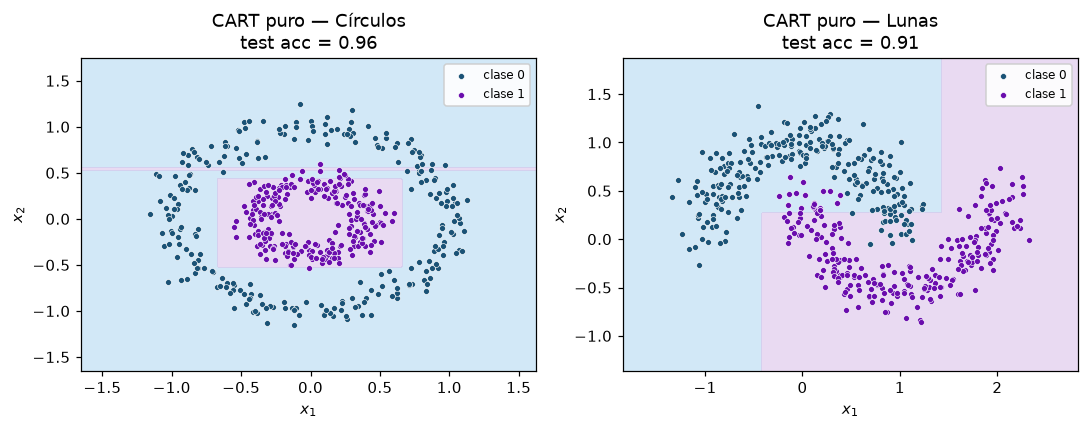

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, (Xtr, ytr, Xte, yte)) in zip(axes, DATASETS.items()):
    cart = DecisionTreeClassifier(max_depth=4, random_state=RNG).fit(Xtr, ytr)
    frontera_decision(cart, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"CART puro — {nombre}\ntest acc = {cart.score(Xte, yte):.2f}")
plt.tight_layout(); plt.show()

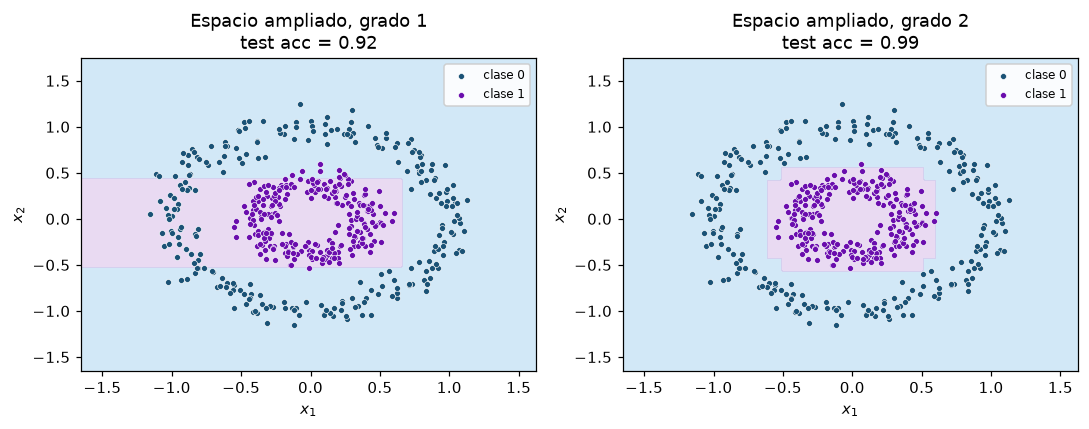

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
Xtr, ytr, Xte, yte = DATASETS["Círculos"]
for ax, grado in zip(axes, [1, 2]):
    pipe = make_pipeline(PolynomialFeatures(grado, include_bias=False),
                         DecisionTreeClassifier(max_depth=3, random_state=RNG)).fit(Xtr, ytr)
    frontera_decision(pipe, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"Espacio ampliado, grado {grado}\ntest acc = {pipe.score(Xte, yte):.2f}")
plt.tight_layout(); plt.show()

Mismo árbol, misma profundidad. Con grado 1 (izquierda) la frontera es la escalera de siempre; con grado 2 (derecha) el árbol encuentra cortes como $x_1^2 + x_2^2 \le t$ y la escalera se vuelve un anillo.

## <FONT SIZE=4 COLOR="red"> 1.3 Explóralo con sliders </FONT>

Juega con el **grado** de $\phi$ y la **profundidad** del árbol:

- En **Círculos**: ¿desde qué grado la frontera se cierra alrededor de la clase del centro? ¿Qué pasa si además subes la profundidad?
- En **Lunas**: el grado 1 con profundidad suficiente ya lo resuelve — curvas no siempre necesarias.
- Ojo con grado alto + profundidad alta: región cada vez más retorcida → sobreajuste (compara train vs test).

In [ ]:
@interact(dataset=Dropdown(options=list(DATASETS), value="Círculos", description="Datos"),
          grado=IntSlider(min=1, max=5, step=1, value=2, description="Grado φ"),
          profundidad=IntSlider(min=1, max=8, step=1, value=3, description="Profundidad"))
def arbol_ampliado(dataset, grado, profundidad):
    Xtr, ytr, Xte, yte = DATASETS[dataset]
    pipe = make_pipeline(PolynomialFeatures(grado, include_bias=False),
                         DecisionTreeClassifier(max_depth=profundidad, random_state=RNG)).fit(Xtr, ytr)
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    frontera_decision(pipe, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"Grado {grado} · φ tiene {pipe[0].n_output_features_} features · prof. {profundidad}")
    plt.tight_layout(); plt.show()
    print(f"Accuracy  train: {pipe.score(Xtr, ytr):.3f}   test: {pipe.score(Xte, yte):.3f}   "
          f"hojas: {pipe[-1].get_n_leaves()}")

interactive(children=(Dropdown(description='Datos', options=('Círculos', 'Lunas'), value='Círculos'), IntSlide…

<div style="background-color:#; border-left:4px solid #6A0DAD; padding:10px 18px; margin:8px 0; border-radius:4px; font-size:14px;">

<p style="font-size:15px; font-weight:600; margin:0 0 8px 0;">Ejercicio A — La geometría escondida</p>

Con **Círculos**, grado 2 y profundidad ~3, la frontera que rodea a la clase central es una cónica. ¿Cuál?

`a)` Una elipse (la circunferencia es su caso particular con coeficientes iguales) &nbsp;
`b)` Una hipérbola &nbsp;
`c)` Una parábola

</div>

In [7]:
respuesta_ejA = "?"   # a, b o c
verificar("ejA_conica", respuesta_ejA)

Incorrecto, intenta de nuevo. Pista: La frontera perfecta para círculos concéntricos es x1² + x2² = r². ¿Qué cónica es esa?


---
# <FONT SIZE=5 COLOR="blue"> 2. Sección B — Árbol con cortes cuadráticos: QDA por nodo </FONT>

## <FONT SIZE=4 COLOR="blue"> 2.1 De dónde sale una frontera curva "con garantías" </FONT>

Elevar features al cuadrado es un truco; cortar con una QDA es un **modelo estadístico completo**. La idea: suponer que cada clase $k$ se genera desde una nube Gaussiana

$$p_k(x) = \frac{1}{(2\pi)^{p/2}\,|\Sigma_k|^{1/2}} \exp\Big(-\tfrac{1}{2}(x - \mu_k)^\top \Sigma_k^{-1} (x - \mu_k)\Big)$$

**¿Qué es cada símbolo?**

- $\mu_k$: el **centro** de la nube de la clase $k$ (vector de medias).
- $\Sigma_k$: su **matriz de covarianza** — codifica forma, orientación y tamaño de la nube (una elipse inclinada es una Gaussiana con covarianza correlacionada).
- $|\Sigma_k|$: determinante, mide el "volumen" de esa nube.
- $(x-\mu_k)^\top \Sigma_k^{-1}(x-\mu_k)$: veremos abajo qué es.

La regla de Bayes asigna $x$ a la clase con mayor $\pi_k \, p_k(x)$, donde $\pi_k$ es el prior (proporción de la clase). Tomando logaritmos (que no cambia el ganador) se obtiene la **función discriminante**:

$$\delta_k(x) = \underbrace{-\tfrac{1}{2}\log|\Sigma_k|}_{\text{volumen de la nube}} \;\; \underbrace{-\tfrac{1}{2}\,(x-\mu_k)^\top \Sigma_k^{-1}(x-\mu_k)}_{\text{distancia de Mahalanobis al cuadrado}} \;\; + \;\; \underbrace{\log \pi_k}_{\text{prior}}$$

**La frontera entre las dos clases** es el empate $\delta_0(x) = \delta_1(x)$. Al expandir los productos matriciales aparecen los términos $x_1^2$, $x_1x_2$, $x_2^2$, $x_1$, $x_2$ y una constante: la **ecuación cuadrática general en dos variables**, cuya gráfica es una cónica — elipse, parábola o hipérbola.

*Dato fino:* si forzamos $\Sigma_0 = \Sigma_1$ (misma forma para ambas clases), los términos cuadráticos se cancelan y la frontera queda **recta**: eso es exactamente LDA. QDA es "LDA liberado".

## <FONT SIZE=4 COLOR="blue"> 2.2 El árbol </FONT>

Espíritu idéntico al greedy de CART, cambiando la búsqueda exhaustiva de umbrales por "entrenar una QDA":

1. En el nodo, ajusta una QDA con los datos que le llegaron.
2. Corta por la frontera: va a la **izquierda** quien tenga $\delta_1(x) - \delta_0(x) \le 0$ y a la derecha el resto. (Ese $\delta_1 - \delta_0$ es justo lo que sklearn llama `decision_function`).
3. Recurre en cada hijo hasta que el nodo sea puro, pequeño (`min_samples_leaf`) o se agote la profundidad.
4. Cada hoja predice por mayoría.

**¿Qué hereda del árbol?** La recursión: un corte cuadrático no separa todo → el siguiente nodo ajusta *otra* cónica sobre los sobrevivientes. La frontera final es el pegamento de varios arcos de cónica.

In [8]:
class ArbolCurvoQDA:
    '''
    Árbol de decisión cuyos cortes son fronteras cuadráticas (cónicas).

    Cada nodo interno ajusta una QDA y divide según el signo de su
    decision_function (δ1 − δ0):  lado izquierdo si ≤ 0, derecho si > 0.
    Cada hoja guarda la clase mayoritaria y sus proporciones.
    '''
    def __init__(self, max_depth=2, min_samples_leaf=5):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self._n_hojas = 0
        self.raiz = self._construir(X, y, profundidad=0)
        return self

    def _hoja(self, y):
        self._n_hojas += 1
        conteo = np.bincount(y, minlength=2)
        return ("hoja", int(conteo.argmax()), conteo / max(len(y), 1), len(y))

    def _construir(self, X, y, profundidad):
        if (np.unique(y).size == 1
                or profundidad >= self.max_depth
                or len(y) < 2 * self.min_samples_leaf):
            return self._hoja(y)
        qda = QuadraticDiscriminantAnalysis().fit(X, y)
        izq = qda.decision_function(X) <= 0
        if izq.sum() < self.min_samples_leaf or (~izq).sum() < self.min_samples_leaf:
            return self._hoja(y)
        return ("nodo", qda,
                self._construir(X[izq], y[izq],  profundidad + 1),
                self._construir(X[~izq], y[~izq], profundidad + 1))

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        salida = np.empty(len(X), dtype=int)
        self._bajar(self.raiz, X, np.arange(len(X)), salida)
        return salida

    def _bajar(self, nodo, X, idx, salida):
        if nodo[0] == "hoja":
            salida[idx] = nodo[1]
            return
        izq = nodo[1].decision_function(X[idx]) <= 0
        self._bajar(nodo[2], X, idx[izq],  salida)
        self._bajar(nodo[3], X, idx[~izq], salida)

    @property
    def n_hojas(self):
        return self._n_hojas

Círculos: hojas = 2
Lunas: hojas = 4


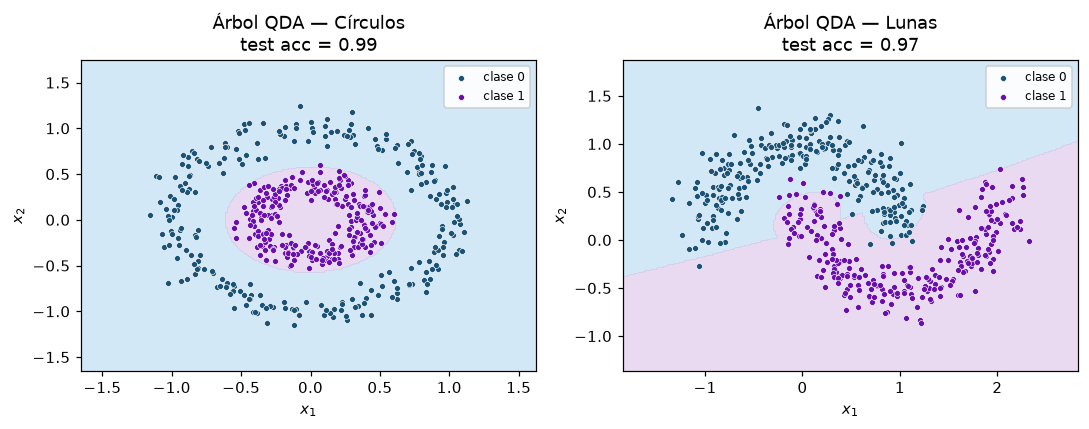

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, (Xtr, ytr, Xte, yte)) in zip(axes, DATASETS.items()):
    arbol = ArbolCurvoQDA(max_depth=2, min_samples_leaf=5).fit(Xtr, ytr)
    frontera_decision(arbol, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"Árbol QDA — {nombre}\ntest acc = {acc(arbol, Xte, yte):.2f}")
    print(f"{nombre}: hojas = {arbol.n_hojas}")
plt.tight_layout(); plt.show()

Con **profundidad 2** (¡una sola cónica interna y dos hojas!) el árbol QDA resuelve los círculos que a CART le costaban 15+ nodos rectos. En las lunas, un solo corte cuadrático ya captura la curvatura general.

## <FONT SIZE=4 COLOR="blue"> 2.3 Explóralo </FONT>

- Baja `max_depth` a 1: un solo corte, la cónica "cruda" que la QDA encuentra en la raíz.
- Sube la profundidad: los arcos de cónica se refinan — pero cada hoja más pequeña es una QDA estimada con menos datos (varianza ↑).

In [ ]:
@interact(dataset=Dropdown(options=list(DATASETS), value="Círculos", description="Datos"),
          max_depth=IntSlider(min=1, max=5, step=1, value=2, description="Profundidad"),
          min_hoja=IntSlider(min=1, max=30, step=1, value=5, description="Mín. hoja"))
def arbol_qda_interactivo(dataset, max_depth, min_hoja):
    Xtr, ytr, Xte, yte = DATASETS[dataset]
    arbol = ArbolCurvoQDA(max_depth=max_depth, min_samples_leaf=min_hoja).fit(Xtr, ytr)
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    frontera_decision(arbol, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"Árbol QDA · prof. {max_depth} · mín. hoja {min_hoja}")
    plt.tight_layout(); plt.show()
    print(f"Accuracy  train: {acc(arbol, Xtr, ytr):.3f}   test: {acc(arbol, Xte, yte):.3f}   "
          f"hojas: {arbol.n_hojas}")

interactive(children=(Dropdown(description='Datos', options=('Círculos', 'Lunas'), value='Círculos'), IntSlide…

<div style="background-color:#; border-left:4px solid #2471A3; padding:10px 18px; margin:8px 0; border-radius:4px; font-size:14px;">

<p style="font-size:15px; font-weight:600; margin:0 0 8px 0;">Ejercicio B — El término exótico de δk</p>

En la función discriminante aparece $(x-\mu_k)^\top \Sigma_k^{-1} (x-\mu_k)$. Ese término es:

`a)` La distancia euclidiana al cuadrado entre $x$ y el centro $\mu_k$ &nbsp;
`b)` La **distancia de Mahalanobis** al cuadrado: mide qué tan lejos está $x$ del centro, pero en "unidades" de la forma y orientación de la nube $\Sigma_k$ &nbsp;
`c)` La varianza de la clase $k$

</div>

In [11]:
respuesta_ejB = "?"   # a, b o c
verificar("ejB_mahalanobis", respuesta_ejB)

Incorrecto, intenta de nuevo. Pista: Fíjate en el papel de Σ_k⁻¹: reescala y rota los ejes antes de medir la distancia.


---
# <FONT SIZE=5 COLOR="green"> 3. Sección C — El árbol híbrido: un clasificador dentro de cada nodo </FONT>

## <FONT SIZE=4 COLOR="green"> 3.1 Todo cabe en una sola ecuación </FONT>

Generalicemos las secciones A y B. Un corte de nodo es cualquier desigualdad

$$f(x) \le 0$$

donde $f$ es la **función de decisión** de un clasificador binario cualquiera:

| Quiero cortar con… | $f(x)$ | Frontera en el plano |
|---|---|---|
| CART (sesión 4) | $x_j - t$ | recta paralela a un eje |
| Árbol oblicuo | $w^\top x - t$ | recta en cualquier dirección |
| Sección B | $\delta_1(x) - \delta_0(x)$ de la QDA | cónica |
| **Aquí** | la de **cualquier** clasificador | la que sea |

**Nodo logístico — el puente con la sesión 3.** La regresión logística modela el logaritmo de las *chances* (odds):

$$\log \frac{P(y = 1 \mid x)}{P(y = 0 \mid x)} = w^\top x + b$$

**¿Qué significa?** El lado izquierdo es el log-odds: $0$ cuando las dos probabilidades empatan, positivo si gana la clase 1. La logística dice que ese log-odds es una función lineal de $x$; su frontera $w^\top x + b = 0$ es una **recta oblicua**. Un árbol con nodos logísticos corta en cualquier dirección (no solo paralela a ejes) y recursa: regiones poligonales, a mitad de camino entre CART y la logística única de la sesión 3.

**Nodo SVM con kernel RBF.** El SVM con kernel radial define

$$f(x) = \sum_{i \in \text{SV}} \alpha_i \, y_i \, \exp\big(-\gamma \,\|x - x_i\|^2\big) + b$$

**¿Cómo leerla?** Cada *vector de soporte* $x_i$ aporta una campana gaussiana centrada en él, con peso $\alpha_i y_i$ (positivo si es de clase 1, negativo si es de clase 0); $f(x)$ es la suma de todas las campanas más el sesgo $b$, y el signo de esa suma decide el lado. Consecuencia práctica de $\gamma$:

- $\gamma$ **pequeña** → campanas anchas que se promedian → frontera suave (más sesgo).
- $\gamma$ **grande** → campanas estrechas, cada punto manda en su vecindad → frontera ondulada (más varianza, sobreajuste).

## <FONT SIZE=4 COLOR="green"> 3.2 El algoritmo </FONT>

1. En cada nodo, **entrena** $f$ (logística o SVM) con los datos que llegaron.
2. Izquierda: $\{x : f(x) \le 0\}$; derecha: el resto.
3. Recurre hasta nodo puro, nodo pequeño o `max_depth`.
4. La hoja predice por mayoría y guarda las proporciones de clase (una "probabilidad" honesta de esa región).

Es CART con el paso 2 generalizado: donde CART *busca* exhaustivamente el mejor umbral, aquí *aprendemos* el corte con un modelo. Precisamente por eso existe toda una literatura (árboles oblicuos OC1, neural decision trees): el espacio de cortes curvos es infinito y hay que aproximarlo.

In [12]:
class ArbolHibrido:
    '''
    Árbol de decisión donde cada nodo interno contiene un clasificador completo.
    El corte del nodo es la frontera de ese clasificador: f(x) <= 0 va a la
    izquierda y f(x) > 0 a la derecha. Las hojas predicen por mayoría.

    `fabrica` debe ser una función SIN argumentos que devuelva un clasificador
    NUEVO ya configurado, por ejemplo:
        lambda: LogisticRegression(max_iter=1000)
        lambda: SVC(kernel="rbf", gamma=0.5)
    '''
    def __init__(self, fabrica, max_depth=2, min_samples_leaf=5):
        self.fabrica = fabrica
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self._n_hojas = 0
        self.raiz = self._construir(X, y, profundidad=0)
        return self

    def _hoja(self, y):
        self._n_hojas += 1
        conteo = np.bincount(y, minlength=2)
        return ("hoja", int(conteo.argmax()), conteo / max(len(y), 1), len(y))

    def _construir(self, X, y, profundidad):
        if (np.unique(y).size == 1
                or profundidad >= self.max_depth
                or len(y) < 2 * self.min_samples_leaf):
            return self._hoja(y)
        clasificador = self.fabrica().fit(X, y)
        izq = clasificador.decision_function(X) <= 0
        if izq.sum() < self.min_samples_leaf or (~izq).sum() < self.min_samples_leaf:
            return self._hoja(y)
        return ("nodo", clasificador,
                self._construir(X[izq], y[izq],  profundidad + 1),
                self._construir(X[~izq], y[~izq], profundidad + 1))

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        salida = np.empty(len(X), dtype=int)
        self._bajar(self.raiz, X, np.arange(len(X)), salida)
        return salida

    def _bajar(self, nodo, X, idx, salida):
        if nodo[0] == "hoja":
            salida[idx] = nodo[1]
            return
        izq = nodo[1].decision_function(X[idx]) <= 0
        self._bajar(nodo[2], X, idx[izq],  salida)
        self._bajar(nodo[3], X, idx[~izq], salida)

    @property
    def n_hojas(self):
        return self._n_hojas

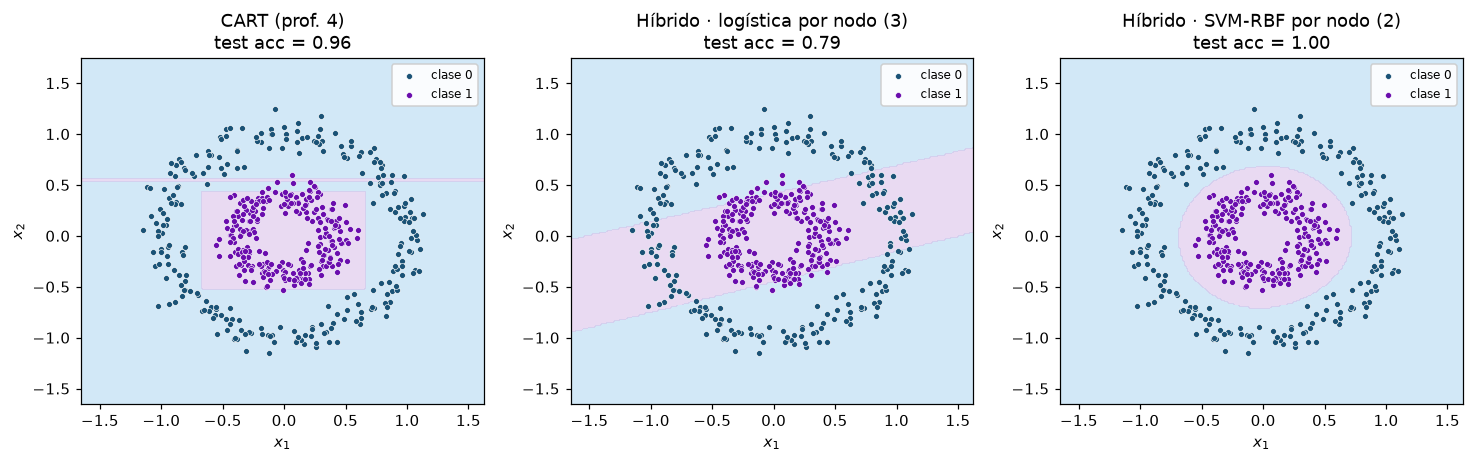

CART (prof. 4)                      train 0.994 | test 0.960 | hojas 7
Híbrido · logística por nodo (3)    train 0.800 | test 0.793 | hojas 4
Híbrido · SVM-RBF por nodo (2)      train 1.000 | test 1.000 | hojas 2


In [13]:
Xtr, ytr, Xte, yte = DATASETS["Círculos"]

modelos = [
    ("CART (prof. 4)",                    DecisionTreeClassifier(max_depth=4, random_state=RNG).fit(Xtr, ytr)),
    ("Híbrido · logística por nodo (3)",  ArbolHibrido(lambda: LogisticRegression(max_iter=1000),
                                                       max_depth=3).fit(Xtr, ytr)),
    ("Híbrido · SVM-RBF por nodo (2)",    ArbolHibrido(lambda: SVC(kernel="rbf", gamma=1.0),
                                                       max_depth=2).fit(Xtr, ytr)),
]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for ax, (nombre, m) in zip(axes, modelos):
    frontera_decision(m, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"{nombre}\ntest acc = {acc(m, Xte, yte):.2f}")
plt.tight_layout(); plt.show()

for nombre, m in modelos:
    hojas = m.get_n_leaves() if hasattr(m, "get_n_leaves") else m.n_hojas
    print(f"{nombre:35s} train {acc(m, Xtr, ytr):.3f} | test {acc(m, Xte, yte):.3f} | hojas {hojas}")

Tres cosas para notar:

1. **La logística por nodo no cierra el círculo**: sus cortes son rectos (oblicuos, pero rectos), así que necesita varios niveles para *aproximar* el anillo con un polígono. Conecta elegantemente la sesión 3 con la 4: es un ensamblaje jerárquico de regresiones logísticas.
2. **El SVM-RBF con profundidad 2 lo clava**: la frontera de la raíz ya es casi el anillo; la recursión solo pule detalles.
3. Cuenta las hojas: flexibilidad no significa más nodos, significa cortes más expresivos.

## <FONT SIZE=4 COLOR="green"> 3.3 Explóralo: botones + sliders </FONT>

Cambia el clasificador de los nodos, la profundidad, $\gamma$ (solo afecta al SVM) y el tamaño mínimo de hoja:

- Logística con profundidad 4 vs profundidad 2: ¿cuántos polígonos necesita para rodear el círculo?
- SVM con $\gamma = 10^2$: frontera con "ecema" — memoriza el ruido (train ↑, test ↓).
- Sube `Mín. hoja` a ~20: corta la recursión antes — regularización por hoja grande, igual que en CART.

In [ ]:
@interact(dataset=Dropdown(options=list(DATASETS), value="Círculos", description="Datos"),
          modelo_nodo=ToggleButtons(options=["Logística", "SVM-RBF"], value="SVM-RBF", description="Nodo:"),
          max_depth=IntSlider(min=1, max=4, step=1, value=2, description="Profundidad"),
          gamma=FloatLogSlider(min=-2, max=2, step=0.1, value=0.5, base=10, description="γ (SVM)"),
          min_hoja=IntSlider(min=1, max=30, step=1, value=5, description="Mín. hoja"))
def arbol_hibrido_interactivo(dataset, modelo_nodo, max_depth, gamma, min_hoja):
    Xtr, ytr, Xte, yte = DATASETS[dataset]
    if modelo_nodo == "Logística":
        fabrica = lambda: LogisticRegression(max_iter=1000)
    else:
        fabrica = lambda: SVC(kernel="rbf", gamma=float(gamma))
    arbol = ArbolHibrido(fabrica, max_depth=max_depth, min_samples_leaf=min_hoja).fit(Xtr, ytr)
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    frontera_decision(arbol, np.vstack([Xtr, Xte]), np.concatenate([ytr, yte]), ax=ax,
                      titulo=f"Híbrido · {modelo_nodo} por nodo · prof. {max_depth}")
    plt.tight_layout(); plt.show()
    print(f"Accuracy  train: {acc(arbol, Xtr, ytr):.3f}   test: {acc(arbol, Xte, yte):.3f}   "
          f"hojas: {arbol.n_hojas}")

interactive(children=(Dropdown(description='Datos', options=('Círculos', 'Lunas'), value='Círculos'), ToggleBu…

<div style="background-color:#; border-left:4px solid #1E8449; padding:10px 18px; margin:8px 0; border-radius:4px; font-size:14px;">

<p style="font-size:15px; font-weight:600; margin:0 0 8px 0;">Ejercicio C — El dial de γ</p>

En el widget anterior (SVM-RBF), mueve $\gamma$ de $10^{-2}$ a $10^{2}$. ¿Qué le ocurre a la frontera?

`a)` Se suaviza hasta volverse casi una recta &nbsp;
`b)` Se vuelve más flexible y ondulada, con riesgo de sobreajuste &nbsp;
`c)` No cambia: $\gamma$ solo afecta a la logística

</div>

In [15]:
respuesta_ejC = "?"   # a, b o c
verificar("ejC_gamma", respuesta_ejC)

Incorrecto, intenta de nuevo. Pista: γ controla el ancho de las campanas gaussianas centradas en los vectores de soporte.


---
# <FONT SIZE=5 COLOR="purple"> 4. Vuelta a los datos reales: heart disease </FONT>

Repitamos la comparación con el dataset de la sesión 4. Para poder **dibujar**, entrenamos con solo dos variables clínicas: `thalach` (frecuencia cardíaca máxima) y `oldpeak` (depresión del ST). Las estandarizamos primero — así los coeficientes de la logística y el $\gamma$ del SVM viven en la misma escala en ambos ejes.

**Advertencia honesta:** entrenar con 2 variables para poder pintar es pedagogía, no buena práctica; el árbol curvo gana aún más cuando no puedes dibujar el espacio, porque nadie corta por ti las 13 dimensiones.

,Modelo,Accuracy train,Accuracy test,Hojas
0,CART (prof. 3),0.759,0.670,8
1,Poly(2) + CART (prof.3),0.759,0.593,8
2,Árbol QDA (prof. 2),0.731,0.659,3
3,Híbrido SVM (prof. 2),0.764,0.747,2


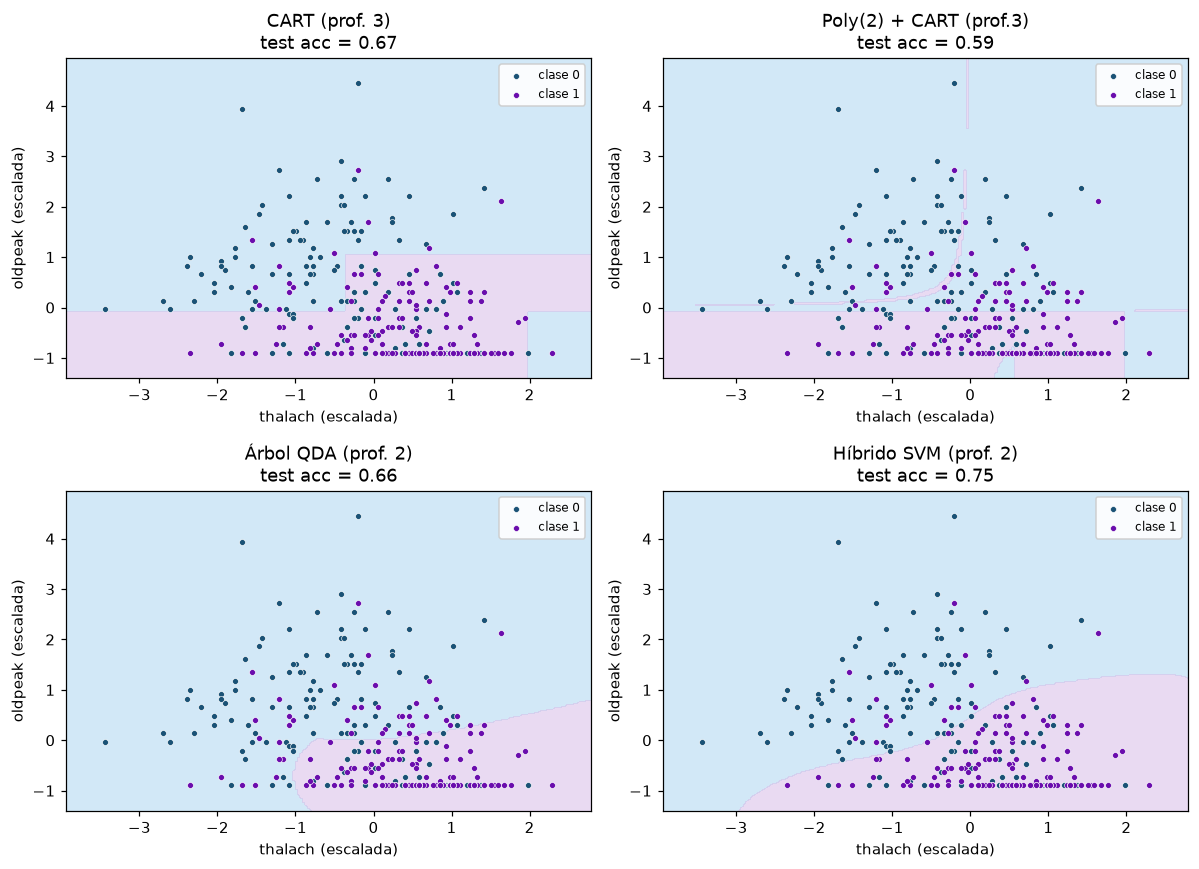

In [16]:
heart = pd.read_csv("https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv")

X_hd = StandardScaler().fit_transform(heart[["thalach", "oldpeak"]].to_numpy())
y_hd = heart["target"].to_numpy()
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(X_hd, y_hd, test_size=0.3,
                                              random_state=RNG, stratify=y_hd)

modelos_hd = {
    "CART (prof. 3)":          DecisionTreeClassifier(max_depth=3, random_state=RNG).fit(Xh_tr, yh_tr),
    "Poly(2) + CART (prof.3)": make_pipeline(PolynomialFeatures(2, include_bias=False),
                                             DecisionTreeClassifier(max_depth=3, random_state=RNG)).fit(Xh_tr, yh_tr),
    "Árbol QDA (prof. 2)":     ArbolCurvoQDA(max_depth=2, min_samples_leaf=10).fit(Xh_tr, yh_tr),
    "Híbrido SVM (prof. 2)":   ArbolHibrido(lambda: SVC(kernel="rbf", gamma=0.5),
                                            max_depth=2, min_samples_leaf=10).fit(Xh_tr, yh_tr),
}

def n_hojas_modelo(m):
    '''Número de hojas: árbol sklearn (get_n_leaves), árbol propio (n_hojas)
    o pipeline (se lo preguntamos a su último paso).'''
    if hasattr(m, "get_n_leaves"):
        return m.get_n_leaves()
    if hasattr(m, "n_hojas"):
        return m.n_hojas
    return n_hojas_modelo(m[-1])

filas = []
for nombre, m in modelos_hd.items():
    filas.append({"Modelo": nombre,
                  "Accuracy train": acc(m, Xh_tr, yh_tr),
                  "Accuracy test":  acc(m, Xh_te, yh_te),
                  "Hojas": n_hojas_modelo(m)})
display(pd.DataFrame(filas).round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (nombre, m) in zip(axes.ravel(), modelos_hd.items()):
    frontera_decision(m, X_hd, y_hd, ax=ax,
                      titulo=f"{nombre}\ntest acc = {acc(m, Xh_te, yh_te):.2f}",
                      etiquetas=("thalach (escalada)", "oldpeak (escalada)"))
plt.tight_layout(); plt.show()

---
# <FONT SIZE=5 COLOR="#6A0DAD"> 5. Reflexión: ¿reinventaste la rueda? </FONT>

**Sí, y por eso valió la pena.** Tu idea tiene nombre y literatura: *oblique trees* (OC1, Murthy 1993; CART-LC en el libro original de Breiman), *functional trees* (Gama 2004), *random rotation forests* (Rodríguez 2006) y *neural decision trees* (Kontschieder 2015; Balestriero 2017). Lo que construiste en la sección C es la versión minimal de esa familia.

**¿Por qué gana CART en la práctica?** Por el costo de *buscar* el corte y por la interpretabilidad:

$$\text{costo por nodo de CART} \;\approx\; O(d \cdot n \log n)$$

**¿Qué dice?** Que basta ordenar los valores de cada una de las $d$ variables ($n \log n$) y probar todos los umbrales: la búsqueda del mejor corte $x_j \le t$ es **exhaustiva y barata**, y el ganador es óptimo dentro de esa familia. En cambio, el espacio de cortes curvos es infinito: no hay lista que recorrer, hay que *aproximar* entrenando un clasificador por nodo (logística, SVM, red) — más caro, más hiperparámetros, y un nodo que ya no se lee como regla clínica ("¿`cp ≤ 0.5`?") sino como "del otro lado de la frontera de un SVM". Perdemos el "por qué" que era la fortaleza del árbol.

**El plot twist industrial:** cuando la práctica quiere árboles con fronteras curvas, no curva los cortes — **combina muchos árboles rectos**: random forest y gradient boosting agregan cientos de escaleras y la frontera resultante es suave y curva. La curvatura sale del ensamblaje, no del nodo.

| | CART | A: Poly + CART | B: QDA por nodo | C: híbrido |
|---|---|---|---|---|
| Frontera por corte | recta paralela a eje | cónica (fija por $\phi$) | cónica (aprendida) | arbitraria |
| Búsqueda del corte | exhaustiva, óptima, barata | exhaustiva en $\phi$ | entrenar QDA | entrenar $f$ |
| Interpretabilidad | reglas claras | media | baja | baja |
| Hiperparámetros | profundidad, hoja | + grado | + nada (¿o sí?) | + los de $f$ (γ, …) |

**Referencias para seguir:**
- Breiman, Friedman, Olshen & Stone (1984). *Classification and Regression Trees* — el original; ya discute combinaciones lineales.
- Murthy, Kasif & Salzberg (1993). *OC1: An Oblique Decision Tree*.
- Rodríguez, Kuncheva & Alonso (2006). *Rotation Forest*.
- Gama (2004). *Functional Trees*.
- Tomita et al. (2020). *Sparse Projection Oblique Randomer Forests*, JMLR.
- Kontschieder et al. (2015). *Deep Neural Decision Forests*, ICCV.

<div style="background-color:#; border-left:4px solid #6A0DAD; padding:10px 18px; margin:8px 0; border-radius:4px; font-size:14px;">

<p style="font-size:15px; font-weight:600; margin:0 0 8px 0;">Ejercicio D — La moraleja </p>

Después de todo lo anterior: ¿por qué scikit-learn implementa CART con cortes paralelos a los ejes y no curvos?

`a)` Porque está demostrado que las curvas nunca mejoran el accuracy &nbsp;
`b)` Porque la búsqueda del mejor corte es exhaustiva y barata (ordenar y probar umbrales), y el resultado se lee como reglas interpretables; las curvas sacrifican interpretabilidad y velocidad por flexibilidad &nbsp;
`c)` Porque las curvas requieren datos normalizados y los cortes por ejes no

</div>

In [17]:
respuesta_ejD = "?"   # a, b o c
verificar("ejD_por_que_cart", respuesta_ejD)

Incorrecto, intenta de nuevo. Pista: Piensa en cuántos candidatos debe evaluar CART en cada nodo, y en cómo se lee un nodo como regla.


---
<div style="background-color:#; border-left:4px solid #6A0DAD; padding:12px 18px; margin:8px 0; border-radius:6px;">

**Cierre.** Construíste tres árboles con fronteras curvas — uno con un truco geométrico ($\phi$), uno con un modelo generativo (QDA) y uno con clasificadores arbitrarios por nodo — y descubriste por qué el humilde CART de cortes rectos sigue reinando: porque a veces la mejor frontera es la que puedes explicar.

Próxima parada natural: **random forest** — la respuesta del mundo real a "quiero árboles más flexibles".

</div>